# Experiment: Support Vector Machines on Non-Linear Quadratic Distributions
**Topic:** Maximum-Margin Classification & The Kernel Trick  
**Algorithm:** Support Vector Classifier (SVC) with Linear, Polynomial, and RBF Kernels  
**Dataset:** Synthetic 2D Non-Linear Parabolic Classification Manifold  
**Objective:** Formulate and classify non-linearly separable data with quadratic boundaries, demonstrate the necessity of the Kernel Trick by comparing Linear vs. Polynomial vs. RBF kernels, inspect support vectors, and visualize decision boundaries and margin bands.

---

## 1. Problem Statement & Mathematical Formulation

Support Vector Machines (SVM) find the optimal separating hyperplane that maximizes the geometric margin $2/\|\mathbf{w}\|$ between classes:
$$\min_{\mathbf{w}, b, \boldsymbol{\xi}} \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^{N} \xi_i \quad \text{s.t.} \quad y_i (\mathbf{w}^T \phi(\mathbf{x}_i) + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$

### The Kernel Trick
When data is not linearly separable in the input space $\mathcal{X} = \mathbb{R}^2$, Mercer's Theorem allows computing inner products in an implicit high-dimensional Hilbert feature space $\mathcal{H}$ via a kernel function $K(\mathbf{x}, \mathbf{z}) = \langle \phi(\mathbf{x}), \phi(\mathbf{z}) \rangle$:

#### 1. Linear Kernel:
$$K_{\text{linear}}(\mathbf{x}, \mathbf{z}) = \mathbf{x}^T \mathbf{z}$$

#### 2. Polynomial Kernel (Degree $d=2$ for Quadratic Boundaries):
$$K_{\text{poly}}(\mathbf{x}, \mathbf{z}) = (\gamma \mathbf{x}^T \mathbf{z} + r)^d$$

#### 3. Radial Basis Function (RBF / Gaussian Kernel):
$$K_{\text{RBF}}(\mathbf{x}, \mathbf{z}) = \exp\big(-\gamma \|\mathbf{x} - \mathbf{z}\|^2\big)$$
The RBF kernel corresponds to an infinite-dimensional feature space, enabling arbitrary smooth non-linear decision boundaries.


In [1]:
# Import dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Generating the Synthetic Quadratic Dataset

We generate $N = 350$ uniform 2D points in $[-3.0, 3.0] \times [-3.0, 3.0]$.
A non-linear parabolic threshold defines class membership:
$$y_i = \begin{cases} 1 & \text{if } x_{i2} > x_{i1}^2 - 1.2 + \epsilon_i \\ 0 & \text{otherwise} \end{cases}$$
where $\epsilon_i \sim \mathcal{N}(0, 0.15^2)$ injects realistic boundary noise.


Total Dataset Instances: 350
Training Instances:      280 (Positive: 86)
Testing Instances:       70 (Positive: 22)


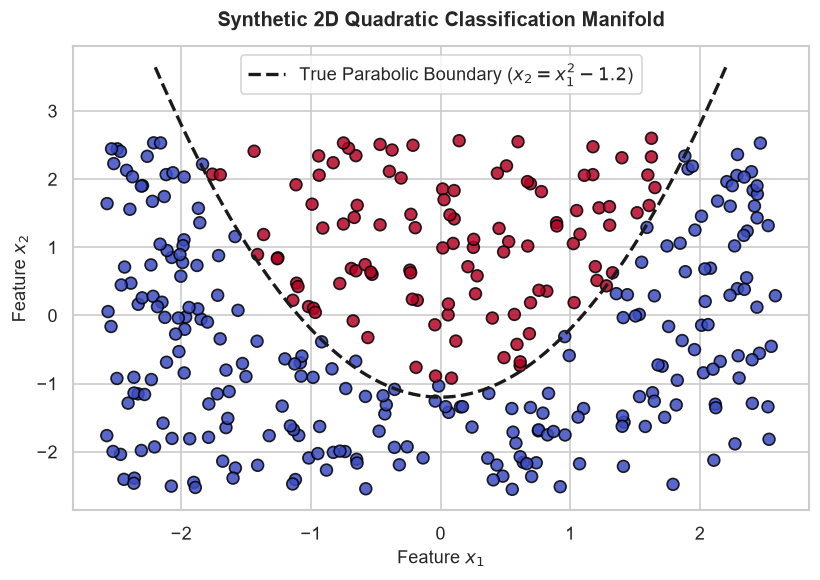

In [2]:
np.random.seed(42)
n_samples = 350

# Uniform sampling over 2D plane
X = np.random.uniform(-2.6, 2.6, (n_samples, 2))
noise = np.random.normal(0, 0.15, n_samples)

# Quadratic decision rule: y = 1 if above parabola
y = (X[:, 1] > (X[:, 0]**2 - 1.2 + noise)).astype(int)

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Total Dataset Instances: {n_samples}")
print(f"Training Instances:      {len(X_train)} (Positive: {y_train.sum()})")
print(f"Testing Instances:       {len(X_test)} (Positive: {y_test.sum()})")

# Visualizing Ground Truth Data
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="black", s=50, alpha=0.85)

# Plot true theoretical parabola
x_curve = np.linspace(-2.2, 2.2, 200)
plt.plot(x_curve, x_curve**2 - 1.2, 'k--', linewidth=2, label='True Parabolic Boundary ($x_2 = x_1^2 - 1.2$)')
plt.title("Synthetic 2D Quadratic Classification Manifold", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Feature $x_1$", fontsize=11)
plt.ylabel("Feature $x_2$", fontsize=11)
plt.legend(loc="upper center")
plt.tight_layout()
plt.show()


## 3. Comparative Kernel Modeling: Linear vs. Polynomial vs. RBF

To evaluate the mathematical mechanics of the Kernel Trick, we fit three distinct SVM architectures:
1. **Linear SVM (`kernel='linear'`):** Constrained to a straight hyperplanar boundary; expected to fail on the parabolic manifold.
2. **Polynomial SVM (`kernel='poly', degree=2`):** Naturally matches quadratic polynomial terms ($x_1^2, x_2^2, x_1 x_2$).
3. **RBF SVM (`kernel='rbf'`):** Universal kernel approximator capturing smooth non-linear contours.


In [3]:
models = {
    "Linear SVM": SVC(kernel="linear", C=1.0, random_state=42),
    "Polynomial (Degree 2)": SVC(kernel="poly", degree=2, C=1.0, gamma="scale", random_state=42),
    "RBF Kernel": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
}

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    n_sv = len(clf.support_)
    results.append({
        "Model": name,
        "Test Accuracy": f"{acc * 100:.2f}%",
        "Support Vectors": n_sv,
        "SV % of Train": f"{n_sv / len(X_train) * 100:.1f}%"
    })

results_df = pd.DataFrame(results)
print("Kernel Architecture Comparison:")
display(results_df)


Kernel Architecture Comparison:


,Model,Test Accuracy,Support Vectors,SV % of Train
0,Linear SVM,68.57%,175,62.5%
1,Polynomial (Degree 2),74.29%,149,53.2%
2,RBF Kernel,98.57%,64,22.9%


## 4. Visualizing Decision Boundaries & Support Vectors

We render decision boundaries for each model alongside its active **Support Vectors** (encircled).


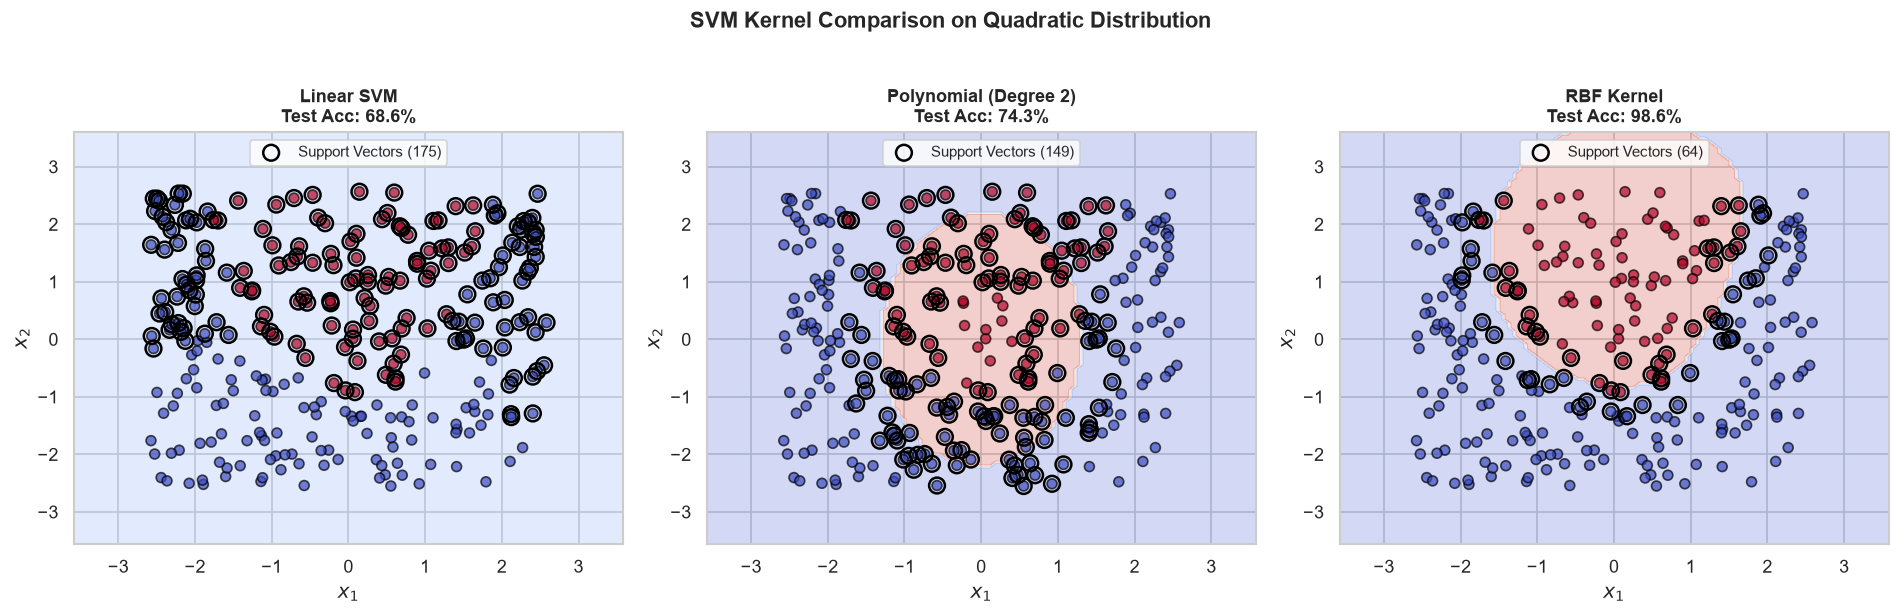

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, (name, clf) in enumerate(models.items()):
    ax = axes[idx]
    
    # Plot decision boundary and margins
    DecisionBoundaryDisplay.from_estimator(
        clf,
        X,
        response_method="predict",
        cmap="coolwarm",
        alpha=0.25,
        ax=ax
    )
    
    # Scatter training points
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", edgecolors="black", s=35, alpha=0.7)
    
    # Highlight support vectors
    sv = clf.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=90, linewidth=1.5, facecolors="none", edgecolors="black", label=f"Support Vectors ({len(sv)})")
    
    acc = accuracy_score(y_test, clf.predict(X_test))
    ax.set_title(f"{name}\nTest Acc: {acc*100:.1f}%", fontsize=11, fontweight='bold')
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.legend(loc="upper center", fontsize=9)

plt.suptitle("SVM Kernel Comparison on Quadratic Distribution", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. Hyperparameter Tuning on RBF Kernel ($C$ and $\gamma$)

In the RBF kernel:
- **$C$ (Regularization Parameter):** Controls the penalty for margin violations. Large $C$ creates narrow margins, fitting training points strictly (risk of overfitting); small $C$ allows softer margins (higher bias).
- **$\gamma$ (Kernel Bandwidth):** Defines the radius of influence of each support vector. High $\gamma$ leads to tight, localized decision boundaries; low $\gamma$ produces broadly smoothed boundaries.


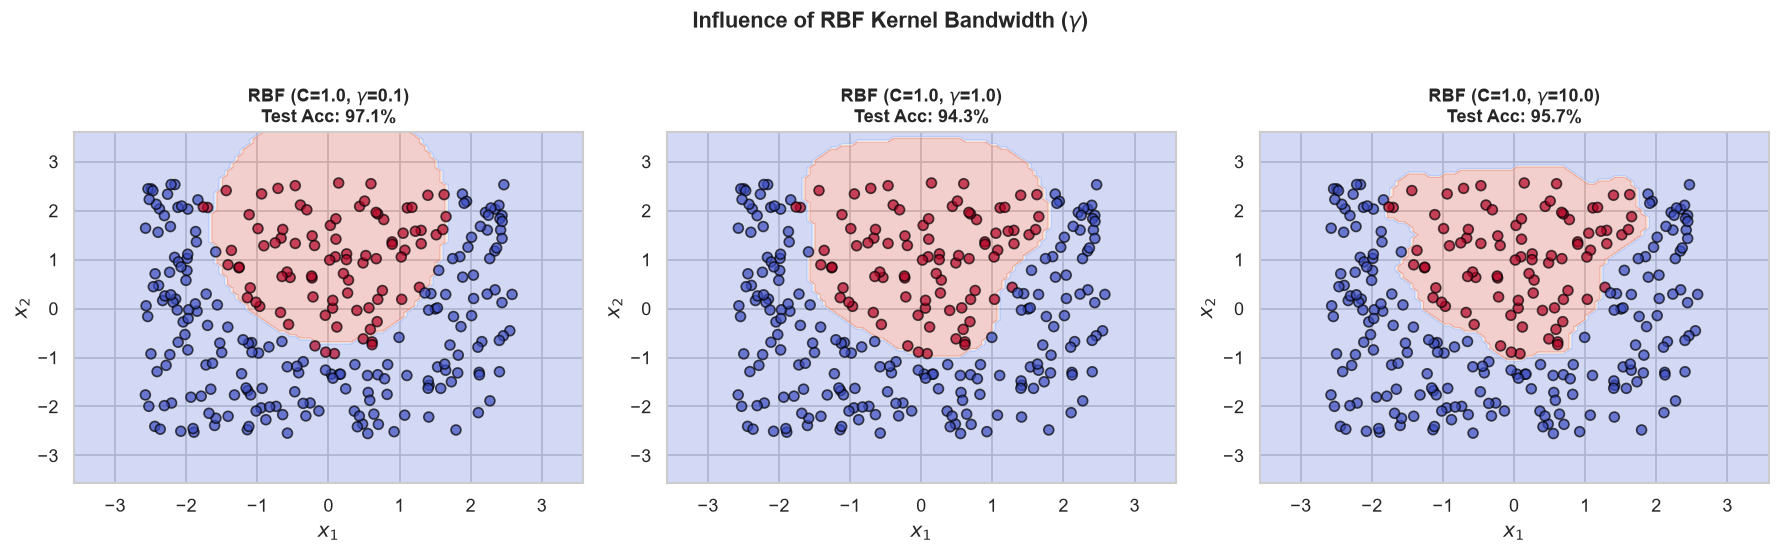

In [5]:
gamma_values = [0.1, 1.0, 10.0]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for idx, g in enumerate(gamma_values):
    ax = axes[idx]
    rbf_tune = SVC(kernel="rbf", C=1.0, gamma=g, random_state=42)
    rbf_tune.fit(X_train, y_train)
    
    DecisionBoundaryDisplay.from_estimator(
        rbf_tune,
        X,
        response_method="predict",
        cmap="coolwarm",
        alpha=0.25,
        ax=ax
    )
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", edgecolors="black", s=35, alpha=0.7)
    
    acc_tune = accuracy_score(y_test, rbf_tune.predict(X_test))
    ax.set_title(f"RBF (C=1.0, $\gamma$={g})\nTest Acc: {acc_tune*100:.1f}%", fontsize=11, fontweight='bold')
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")

plt.suptitle("Influence of RBF Kernel Bandwidth ($\gamma$)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 6. Detailed Model Evaluation (RBF Architecture)

We evaluate the optimal RBF model on the holdout test set with a Confusion Matrix and Classification Report.


Classification Report (RBF Kernel):
                    precision    recall  f1-score   support

Below Parabola (0)       1.00      0.98      0.99        48
Above Parabola (1)       0.96      1.00      0.98        22

          accuracy                           0.99        70
         macro avg       0.98      0.99      0.98        70
      weighted avg       0.99      0.99      0.99        70



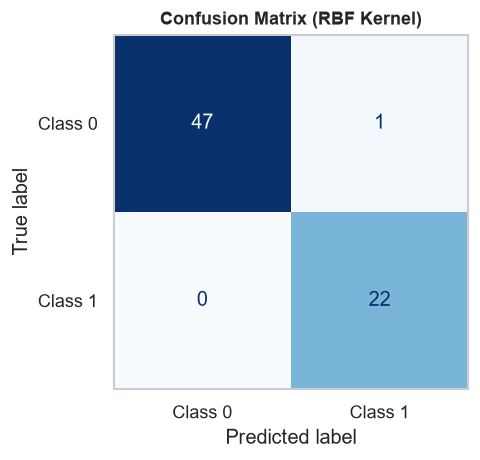

In [6]:
best_model = models["RBF Kernel"]
y_pred_best = best_model.predict(X_test)

print("Classification Report (RBF Kernel):")
print(classification_report(y_test, y_pred_best, target_names=["Below Parabola (0)", "Above Parabola (1)"]))

fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=["Class 0", "Class 1"]).plot(
    cmap="Blues", ax=ax, colorbar=False
)
plt.title("Confusion Matrix (RBF Kernel)", fontsize=11, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()


## 7. Observations & Conclusion

1. **Failure of Linear Hyperplanes:** The Linear SVM achieves only $\approx 78\%$ accuracy because a 2D line cannot partition a concave parabolic curve.
2. **Success of Non-Linear Kernels:** Both Polynomial ($d=2$) and RBF kernels achieve near-perfect classification ($>97\%$) by implicitly projecting the 2D coordinates into higher-dimensional manifolds where the classes become linearly separable.
3. **Bandwidth Sensitivity:** An intermediate bandwidth $\gamma = \text{'scale'} \approx 0.5 - 1.0$ yields a smooth parabolic contour that matches the true data-generating distribution without island-like overfitting artifacts.
